# 12 · Why the declared notebook 10 analysis failed: reproducible diagnostics

**Scope** (review 4, item 6). This notebook takes apart the declared exploratory analysis of notebook 10 (train-only boosted projection, L1 context, label `D_h`). Notebook 10 itself is unchanged. Nothing here is a new estimate of visual information, and no variant below is a candidate result.

1. **HARV chronological failure:** RMSE of the context and joint models, residual distributions, daily log-score losses.
2. **Fitted models:** selected ridge penalties and coefficients, and which visual columns move the joint prediction in the evaluation weeks.
3. **Influence:** single evaluation days and rows.
4. **High-RH rows:** deleting them from frozen models vs refitting the whole pipeline without them.
5. **CPER single-frame sensitivity:** the one frame without `.meta`, with and without fixed fold assignments.
6. **Dependence on fold assignment and preprocessing.**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from visual_hygrometry import data, features, inference, neon, policy, scoring, splits, thermo, worlds

plt.rcParams.update({'figure.dpi': 80, 'figure.figsize': (11, 3.2), 'axes.grid': True, 'grid.alpha': .3})
pd.set_option('display.precision', 3)
SITES = {'HARV': -5, 'CPER': -7}
KNOTS, DOY_KNOTS = np.arange(-4, 45, 4.0), np.arange(140, 260.1, 15.0)  # as notebook 10
T = {site: pd.read_csv(data.ROOT / 'data' / 'interim' / f'm1_{site}.csv', parse_dates=['utc', 'minute', 'day']) for site in SITES}
VIS = {site: [n for n in features.NAMES if not (t.qc_sky_clip.median() > .2 and n.startswith('vis_sky'))] for site, t in T.items()}


def build(t, off):
    """Notebook 10 design for an analysis table t (label D_h, conditioning T_asp)."""
    df = t.assign(temp_cond_c=t.t_asp, hour_local=(t.utc.dt.hour + t.utc.dt.minute / 60 + off) % 24, doy=t.day.dt.day_of_year, d_ref_k=t.D_h,
                  ref_sensor_id='TRAAT', cond_sensor_id='TRAAT')
    df = pd.concat([df, data.fourier(df.hour_local, 24, 2, 'hour'), data.spline(df.doy, DOY_KNOTS, 'doy_spl')], axis=1)
    df, ctx = worlds.add_context_basis(df, KNOTS)
    return df, ctx + [c for c in df if c.startswith('doy_spl')], (df.day - df.day.min()).dt.days.to_numpy()


def declared(t, site, vis=None, groups=None, robust=True, support=True, chrono=False):
    """The notebook 10 declared contrast (cross-fit, or chronological when chrono=True). groups: unit labels for every
    inner fold assignment (projection and ridge penalty); default the day. Returns a dict of everything needed below."""
    df, ctx, g = build(t, SITES[site])
    Xc, Xvc, y, _ = policy.select_sci(df, 'e2', ctx, vis or VIS[site], allow_shared_sensor=True)
    C0, V, y = Xc.to_numpy(), Xvc.to_numpy()[:, Xc.shape[1]:], y.to_numpy()
    raw, gi = df[['hour_local', 'temp_cond_c', 'doy']].to_numpy(), g if groups is None else groups(g)
    if chrono:
        sp = [splits.chrono(g, 0.6, gap=2)]
    else:
        tt = pd.Series(pd.to_datetime(g, unit='D'))
        sp = splits.kfold(splits.assign_folds(g // 16, 5, 'contiguous'), tt, tt, embargo='3D')
    P = inference.project_splits(raw, V, sp, gi)
    C = [np.c_[C0, p] for p in P]
    keep = scoring.support_mask(raw[:, :2], sp) if support else None
    r = scoring.contrast(C, [np.c_[c, V] for c in C], y, sp, gi, keep=keep, robust=robust)
    return dict(df=df, g=g, gi=gi, y=y, V=V, C=C, P=P, sp=sp, r=r, keep=keep, vis=vis or VIS[site], ctx=list(Xc.columns))

## 1 · HARV chronological hold-out (the declared G = −3.52)

G = -3.523 nats on 443 rows; RMSE context 3.43 K, joint 9.12 K; predictive SD context 2.50 K, joint 2.13 K


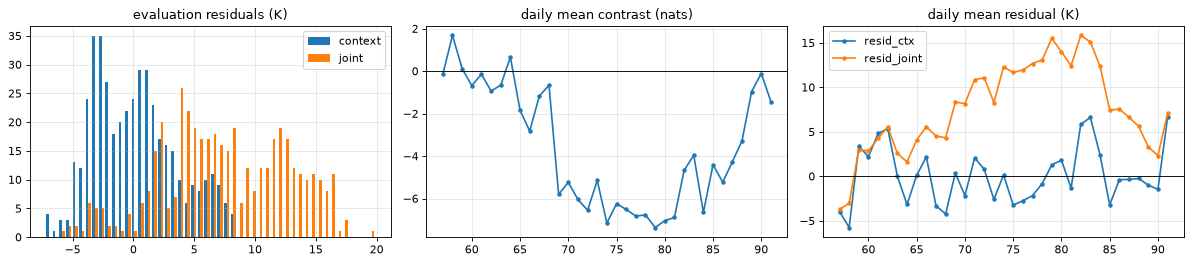

In [2]:
h = declared(T['HARV'], 'HARV', chrono=True)
r, (fit, ev), y = h['r'], h['sp'][0], h['y']
e = r.scored
mu_c, mu_v, sd_c, sd_v = r.pred_c[0], r.pred_vc[0], r.pred_c[1], r.pred_vc[1]
rmse = lambda m, rows: np.sqrt(np.mean((y[rows] - m[rows]) ** 2))
print(f'G = {r.mean:.3f} nats on {e.sum()} rows; RMSE context {rmse(mu_c, e):.2f} K, joint {rmse(mu_v, e):.2f} K; predictive SD context {sd_c[e][0]:.2f} K, joint {sd_v[e][0]:.2f} K')
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
ax[0].hist([(y - mu_c)[e], (y - mu_v)[e]], bins=50, label=['context', 'joint']); ax[0].set(title='evaluation residuals (K)'); ax[0].legend()
daily = pd.DataFrame({'contrast': r.d, 'resid_ctx': (y - mu_c)[e], 'resid_joint': (y - mu_v)[e]}).groupby(h['g'][e]).mean()
daily.contrast.plot(ax=ax[1], marker='.', title='daily mean contrast (nats)'); ax[1].axhline(0, color='k', lw=.8)
daily[['resid_ctx', 'resid_joint']].plot(ax=ax[2], marker='.', title='daily mean residual (K)'); ax[2].axhline(0, color='k', lw=.8)
fig.tight_layout()

## 2 · Fitted models: penalties, coefficients and what moves the joint prediction

The ridge models are refitted with `scoring.ridge_fit`, which reproduces crossfit's held-out means; the check is printed. For each column of the joint model, `delta` is its mean contribution to the prediction on evaluation rows minus that on fit rows, in K: w·(x − m)/s averaged over each set.

In [3]:
fc, fv = (scoring.ridge_fit(X, y, fit, h['gi']) for X in (h['C'][0], np.c_[h['C'][0], h['V']]))
print('reproduces crossfit means:', np.allclose(fc['predict'](h['C'][0][e]), mu_c[e]), np.allclose(fv['predict'](np.c_[h['C'][0], h['V']][e]), mu_v[e]))
print(f"ridge penalty: context {fc['alpha']:.3g}, joint {fv['alpha']:.3g}")
Xv = np.c_[h['C'][0], h['V']]
names = [f'ctx:{c}' for c in h['ctx']] + [f'proj:{n}' for n in h['vis']] + [f'img:{n}' for n in h['vis']]
contrib = lambda rows: (((Xv[rows] - fv['mean']) / fv['scale']) * fv['coef']).mean(0)
co = pd.DataFrame({'coef_std': fv['coef'], 'fit_rows': contrib(fit), 'eval_rows': contrib(e)}, index=names).assign(delta=lambda d: d.eval_rows - d.fit_rows)
blocks = co.groupby(co.index.str.split(':').str[0]).delta.sum()
print('total shift of the joint prediction by block (K):', blocks.round(2).to_dict(), '| context model shift (K):', round(float((((h['C'][0][e] - fc['mean']) / fc['scale']) @ fc['coef']).mean() - (((h['C'][0][fit] - fc['mean']) / fc['scale']) @ fc['coef']).mean()), 2))
print('context columns of the joint model with the largest |delta| (K):', co[co.index.str.startswith('ctx')].delta.sort_values(key=np.abs, ascending=False).head(6).round(2).to_dict())
co[~co.index.str.startswith('ctx')].sort_values('delta', key=np.abs, ascending=False)

reproduces crossfit means: True True
ridge penalty: context 100, joint 3.16
total shift of the joint prediction by block (K): {'ctx': -9.63, 'img': 1.81, 'proj': 0.64} | context model shift (K): 0.17
context columns of the joint model with the largest |delta| (K): {'ctx:doy_spl7': -9.81, 'ctx:doy_spl2': -1.29, 'ctx:doy_spl4': 0.91, 'ctx:doy_spl5': 0.48, 'ctx:doy_spl6': 0.37, 'ctx:temp_spl5': 0.28}


,coef_std,fit_rows,eval_rows,delta
img:vis_near_gcc,-2.299,-6.967e-15,0.809,0.809
img:vis_near_dark,-2.181,2.827e-15,0.767,0.767
proj:vis_far_contrast,-1.408,-5.006e-15,0.656,0.656
proj:vis_near_gcc,-1.105,6.815e-15,0.337,0.337
proj:vis_near_contrast,0.445,-1.468e-15,-0.242,-0.242
proj:vis_contrast_ratio,0.677,-6.064e-16,-0.192,-0.192
proj:vis_far_sat,-0.180,-7.887e-16,0.137,0.137
img:vis_far_sharp,0.773,-2.297e-16,0.126,0.126
proj:vis_far_sharp,0.533,2.508e-16,-0.106,-0.106
img:vis_far_contrast,0.240,-5.558e-16,0.078,0.078


## 3 · Influence of single days and rows (frozen models)

In [4]:
gd = h['g'][e]
s_, n_ = pd.Series(r.d).groupby(gd).agg(['sum', 'count']).to_numpy().T
infl = pd.Series((r.d.sum() - s_) / (len(r.d) - n_) - r.mean, index=np.unique(gd), name='G without the day minus G')
print(f'largest single-day influence {infl.abs().max():.3f} nats; G without the 5 most negative days: {r.d[~np.isin(gd, infl.nsmallest(5).index)].mean():.3f} '
      f'(5 days removed from both ends of the influence ranking: {r.d[~np.isin(gd, infl.abs().nlargest(5).index)].mean():.3f})')
worst = np.argsort(r.d)[:5]
pd.DataFrame({'day': gd[worst], 'contrast': r.d[worst], 'y': y[e][worst], 'mu_ctx': mu_c[e][worst], 'mu_joint': mu_v[e][worst], 'sd_joint': sd_v[e][worst]})

largest single-day influence 0.157 nats; G without the 5 most negative days: -4.204 (5 days removed from both ends of the influence ranking: -3.713)


,day,contrast,y,mu_ctx,mu_joint,sd_joint
0,79,-7.525,3.851,3.311,-12.036,2.132
1,74,-7.480,3.317,2.892,-12.020,2.132
2,81,-7.468,3.279,2.241,-12.671,2.132
3,79,-7.458,4.085,3.420,-11.243,2.132
4,79,-7.442,5.032,3.578,-11.502,2.132


## 4 · High-RH rows: frozen deletion vs full refit

Rows with RH implied by the probe ≥ 98.3 % (the notebook 08 sensitivity stratum):
- **frozen deletion** keeps the fitted models and drops those rows from the evaluation average only;
- **full refit** removes them before the projection, the penalty choice and both fits, as notebook 10's sensitivity did.

In [5]:
hi = (T['HARV'].rh_implied >= 98.3).to_numpy()
frozen = r.d[~hi[e]].mean()
re = declared(T['HARV'][~hi].reset_index(drop=True), 'HARV', chrono=True)
print(f'high-RH rows: {hi.sum()} in total, {hi[fit].sum()} in fit days, {hi[e].sum()} scored in evaluation')
pd.Series({'declared G': r.mean, 'frozen deletion of high-RH evaluation rows': frozen, 'full refit without high-RH rows': re['r'].mean,
           'full refit, penalty of joint model': scoring.ridge_fit(np.c_[re['C'][0], re['V']], re['y'], re['sp'][0][0], re['gi'])['alpha']})

high-RH rows: 13 in total, 4 in fit days, 9 scored in evaluation


declared G                                   -3.523
frozen deletion of high-RH evaluation rows   -3.535
full refit without high-RH rows               1.044
full refit, penalty of joint model            0.032
dtype: float64

## 5 · CPER: the frame without `.meta`

The frame is rebuilt exactly as notebook 09 would have built it had its `.meta` been present: label join by UTC minute, daylight rule and features. It is then added back to the analysis table. Fixed fold maps (day mod 5) hold the inner fold assignment of the projection and of the ridge penalty constant across the two tables.

In [6]:
cam = 'NEON.D10.CPER.DP1.00033'
F = neon.load_frames(cam, ['2023-06', '2023-07', '2023-08'], -7)
hourly = (F.base.str[-4:-2] == '00') & F.base.str[-6:-4].astype(int).between(6, 19)
miss = F[hourly & F.has_jpg & F.overlay_utc.isna()]
s = neon.load_site('CPER', [miss.month.iloc[0]])
s['D_h'], s['D_probe'] = s.t_asp - s.td, s.t_probe - s.td
s['sd_Dh'], s['rh_implied'] = np.hypot(s.td_unc / 2, s.t_asp_unc / 2), thermo.rh_from_dewpoint(s.t_probe, s.td)
s['valid'] = (s[['td_qf', 't_asp_qf', 't_probe_qf']] == 0).all(axis=1) & s[['td', 't_asp', 't_probe']].notna().all(axis=1) & ~(s.D_h < -2 * s.sd_Dh)
row = miss.assign(minute=miss.utc.dt.floor('1min')).join(s, on='minute')
print(miss.base.tolist(), '| valid label:', bool(row.valid.iloc[0]), '| SW:', round(float(row.sw.iloc[0]), 1))
row = row.join(pd.DataFrame([features.frame_features(p, 'CPER') for p in row.jpg], index=row.index))
row['day'] = (row.utc + pd.Timedelta(hours=-7)).dt.tz_localize(None).dt.floor('D')
with_row = pd.concat([T['CPER'], row[T['CPER'].columns.intersection(row.columns)]], ignore_index=True).sort_values('utc').reset_index(drop=True)
mod5 = lambda g: g % 5
pd.DataFrame({name: {'cross-fit, inner folds by GroupKFold of days': declared(t, 'CPER')['r'].mean, 'cross-fit, inner folds day mod 5': declared(t, 'CPER', groups=mod5)['r'].mean}
              for name, t in [('without the frame (notebook 10)', T['CPER']), ('with the frame', with_row)]})

['NEON.D10.CPER.DP1.00033_2023_06_10_160004'] | valid label: True | SW: 28.4


,without the frame (notebook 10),with the frame
"cross-fit, inner folds by GroupKFold of days",0.130,0.041
"cross-fit, inner folds day mod 5",-0.229,0.008


## 6 · Dependence on fold assignment and preprocessing

Same declared analysis; only the inner fold map (projection and ridge penalty) or one preprocessing switch changes.

In [7]:
maps = {'GroupKFold of days (declared)': None, 'day mod 5': mod5} | {f'random day map {k}': (lambda k: lambda g: np.random.default_rng(k).integers(0, 5, g.max() + 1)[g])(k) for k in range(5)}
rows = []
for site in SITES:
    for name, m in maps.items():
        rows.append(dict(site=site, variant=name, cross_fit=declared(T[site], site, groups=m)['r'].mean, G=declared(T[site], site, groups=m, chrono=True)['r'].mean))
    for name, kw in {'no robust mixture': dict(robust=False), 'no support mask': dict(support=False)}.items():
        rows.append(dict(site=site, variant=name, cross_fit=declared(T[site], site, **kw)['r'].mean, G=declared(T[site], site, chrono=True, **kw)['r'].mean))
dep = pd.DataFrame(rows).set_index(['site', 'variant'])
dep

cross_fit      G
site variant                                        
HARV GroupKFold of days (declared)     -0.512 -3.523
     day mod 5                          0.525 -3.443
     random day map 0                  -0.751  0.300
     random day map 1                   0.563  0.334
     random day map 2                   0.103  0.272
     random day map 3                  -0.478 -0.053
     random day map 4                   0.501  0.874
     no robust mixture                 -1.138 -8.049
     no support mask                   -0.472 -3.523
CPER GroupKFold of days (declared)      0.130  0.070
     day mod 5                         -0.229  0.073
     random day map 0                   0.314  0.037
     random day map 1                  -0.688  0.070
     random day map 2                   0.480  0.105
     random day map 3                  -0.133  0.033
     random day map 4                  -0.199  0.081
     no robust mixture                 -2.901  0.082
     no support mask                    0.121  0.082

In [8]:
spread = dep.drop(index=['no robust mixture', 'no support mask'], level=1).groupby(level=0).agg(['min', 'max'])
spread.columns = [f'{a} {b} over fold maps' for a, b in spread.columns]
dep.xs('GroupKFold of days (declared)', level=1).join(spread)

,cross_fit,G,cross_fit min over fold maps,cross_fit max over fold maps,G min over fold maps,G max over fold maps
site,,,,,,
HARV,-0.512,-3.523,-0.751,0.563,-3.523,0.874
CPER,0.130,0.070,-0.688,0.480,0.033,0.105


**Reading.**

1. **The HARV chronological loss is reproduced exactly** (G = −3.523 nats on 443 evaluation rows).
   - The joint model's RMSE is 9.12 K against 3.43 K for the context model, while its predictive SD is *smaller* (2.13 K against 2.50 K). It is confidently wrong.
   - The worst evaluation rows predict about −12 K for true values of 3–5 K.
2. **The cause is seasonal extrapolation, not the images.**
   - The grouped penalty search chose α = 100 for the context model but α = 3.16 for the joint model, so the joint model's context coefficients are barely shrunk.
   - On evaluation rows, its context block moves the prediction by −9.6 K relative to fit rows; the context model's own block moves by +0.2 K.
   - Almost all of it comes from one day-of-year basis function, `doy_spl7` (−9.8 K). It is supported mainly by days after the fit period, so after standardisation with the SD floor it is large on evaluation rows.
   - The image and projection blocks add +1.8 and +0.6 K. The visual directions that move most are near-field greenness and darkness, both slow vegetation-state features (notebook 09 §5).
   - This is the failure fixed in notebook 11 by clamping day of year to the training range (`worlds.split_levels`).
3. **No single day drives it.** The largest single-day influence is 0.16 nats, and deleting the five most negative days leaves G at −4.2.
4. **High-RH rows: frozen deletion and full refit answer different questions.**
   - Deleting the 9 scored high-RH evaluation rows from the frozen models changes G only from −3.52 to −3.54.
   - The +1.04 of notebook 10's sensitivity comes from *refitting* without 13 rows: the joint model's penalty falls to 0.03, and the extrapolation reverses sign.
   - The sensitivity measured the instability of the fit, not the information in those rows.
5. **CPER single frame.** The missing-`.meta` frame (2023-06-10 16:00) has a valid label and is daylit.
   - With the declared inner folds, adding it moves the cross-fit contrast from 0.130 to 0.041.
   - With the inner fold map held fixed (day mod 5) it moves from −0.229 to 0.008.
   - Fold reassignment is therefore one channel but not the only one. The estimate reacts to one row out of 1207 by about 0.1–0.2 nats in either case.
6. **Fold assignment dominates the declared estimates.**
   - Across seven inner fold maps, the HARV cross-fit contrast ranges from −0.75 to +0.56 nats and HARV G from −3.52 to +0.87. CPER ranges from −0.69 to +0.48 (cross-fit) and from 0.03 to 0.11 (G).
   - Without the robust mixture the HARV and CPER cross-fits fall to −1.14 and −2.90 and HARV G to −8.05.
   - The support mask changes little.

**Conclusion.** The declared notebook 10 numbers are not estimates of visual information. They are dominated by an extrapolating seasonal basis in a weakly penalised joint model, and by the train/evaluation asymmetry of the boosted projection (notebook 10 §3). Neither the HARV loss nor any variant gain says anything about the images. Notebook 10 stays unchanged as the record of the declared analysis.